# CALCULO DA TENSÃO

-----------------------------------------------------------------
 RESULTADOS DA ANÁLISE MECÂNICA - COBRE C11000
 (Valores atualizados conforme tabela de medições térmicas)
-----------------------------------------------------------------
Média Operacional Diária (T = 39.0°C) - Operação 24/7:
 -> Tensão Térmica: 27.85 MPa | Fator de Segurança: 8.98

Pico em Estresse (T = 55.0°C) - Margem de 50°C para Tcrit:
 -> Tensão Térmica: 59.67 MPa | Fator de Segurança: 4.19

Alerta do Fabricante - Thigh (T = 85.0°C) - Margem de 30°C para Pico:
 -> Tensão Térmica: 119.34 MPa | Fator de Segurança: 2.09

Limite Crítico - Tcrit (T = 105.0°C):
 -> Tensão Térmica: 159.12 MPa | Fator de Segurança: 1.57
-----------------------------------------------------------------


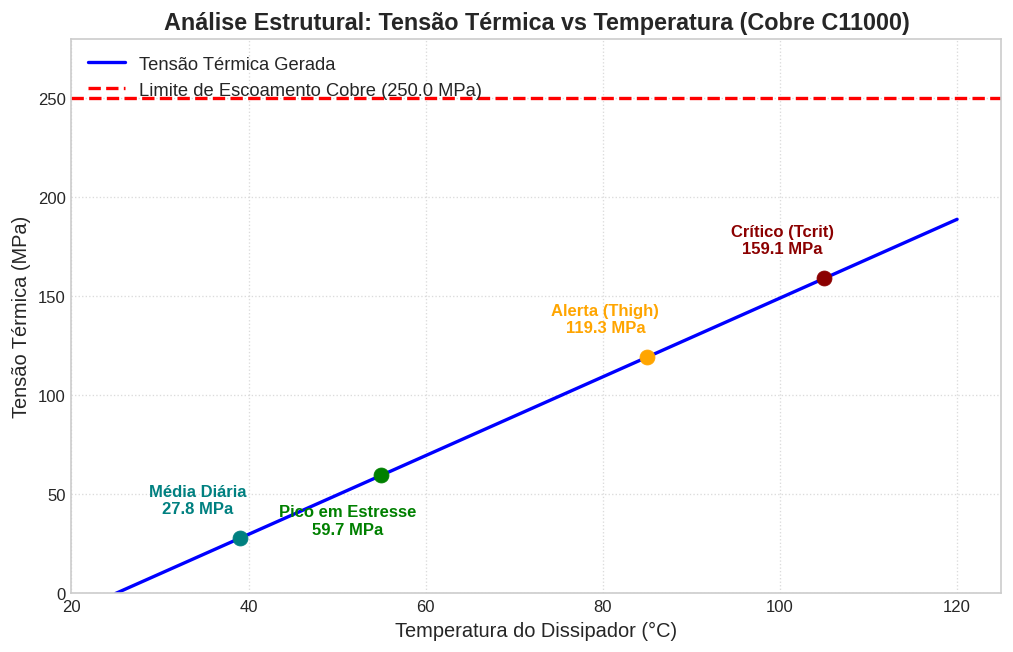

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# 1. DADOS DE ENTRADA (Material: Cobre C11000)
# ==============================================================================
E = 117.0e9             # Módulo de Elasticidade (Pa) -> 117 GPa
alpha = 17.0e-6         # Coeficiente de Expansão Térmica Linear (1/°C)
sigma_y = 250.0         # Limite de Escoamento (MPa) - Ponto de falha plástica

# Temperaturas extraídas da tabela do projeto (Computador Medidas)
T0 = 25.0               # Temperatura ambiente base (°C)
T_med = 39.0            # Média Operacional Diária (~38-40°C)
T_op = 55.0             # Pico em Estresse medido (°C)
T_high = 85.0           # Alerta do Fabricante / Thigh (°C)
T_crit = 105.0          # Limite Crítico / Tcrit (°C)

# ==============================================================================
# 2. CÁLCULO DE TENSÃO E FATOR DE SEGURANÇA
# ==============================================================================
def analisar_tensao(T_final):
    delta_T = T_final - T0
    tensao_MPa = (E * alpha * delta_T) / 1e6
    fs = sigma_y / tensao_MPa
    return tensao_MPa, fs

tensao_med, fs_med = analisar_tensao(T_med)
tensao_op, fs_op = analisar_tensao(T_op)
tensao_high, fs_high = analisar_tensao(T_high)
tensao_crit, fs_crit = analisar_tensao(T_crit)

print("-" * 65)
print(" RESULTADOS DA ANÁLISE MECÂNICA - COBRE C11000")
print(" (Valores atualizados conforme tabela de medições térmicas)")
print("-" * 65)
print(f"Média Operacional Diária (T = {T_med}°C) - Operação 24/7:")
print(f" -> Tensão Térmica: {tensao_med:.2f} MPa | Fator de Segurança: {fs_med:.2f}\n")

print(f"Pico em Estresse (T = {T_op}°C) - Margem de 50°C para Tcrit:")
print(f" -> Tensão Térmica: {tensao_op:.2f} MPa | Fator de Segurança: {fs_op:.2f}\n")

print(f"Alerta do Fabricante - Thigh (T = {T_high}°C) - Margem de 30°C para Pico:")
print(f" -> Tensão Térmica: {tensao_high:.2f} MPa | Fator de Segurança: {fs_high:.2f}\n")

print(f"Limite Crítico - Tcrit (T = {T_crit}°C):")
print(f" -> Tensão Térmica: {tensao_crit:.2f} MPa | Fator de Segurança: {fs_crit:.2f}")
print("-" * 65)

# ==============================================================================
# 3. GERAÇÃO DO GRÁFICO
# ==============================================================================
temperaturas = np.linspace(25, 120, 100)
tensoes = (E * alpha * (temperaturas - T0)) / 1e6

plt.figure(figsize=(10, 6))
plt.plot(temperaturas, tensoes, label='Tensão Térmica Gerada', color='blue', linewidth=2)
plt.axhline(y=sigma_y, color='red', linestyle='--', linewidth=2,
            label=f'Limite de Escoamento Cobre ({sigma_y} MPa)')

# Pontos de Temperatura extraídos da Tabela
plt.scatter([T_med], [tensao_med], color='teal', zorder=5, s=80)
plt.annotate(f'Média Diária\n{tensao_med:.1f} MPa', (T_med, tensao_med),
             textcoords="offset points", xytext=(-25, 15), ha='center', color='teal', weight='bold')

plt.scatter([T_op], [tensao_op], color='green', zorder=5, s=80)
# Deslocado para baixo para não sobrepor o texto da média diária
plt.annotate(f'Pico em Estresse\n{tensao_op:.1f} MPa', (T_op, tensao_op),
             textcoords="offset points", xytext=(-20, -35), ha='center', color='green', weight='bold')

plt.scatter([T_high], [tensao_high], color='orange', zorder=5, s=80)
plt.annotate(f'Alerta (Thigh)\n{tensao_high:.1f} MPa', (T_high, tensao_high),
             textcoords="offset points", xytext=(-25, 15), ha='center', color='orange', weight='bold')

plt.scatter([T_crit], [tensao_crit], color='darkred', zorder=5, s=80)
plt.annotate(f'Crítico (Tcrit)\n{tensao_crit:.1f} MPa', (T_crit, tensao_crit),
             textcoords="offset points", xytext=(-25, 15), ha='center', color='darkred', weight='bold')

plt.title('Análise Estrutural: Tensão Térmica vs Temperatura (Cobre C11000)', fontsize=14, weight='bold')
plt.xlabel('Temperatura do Dissipador (°C)', fontsize=12)
plt.ylabel('Tensão Térmica (MPa)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(loc='upper left', fontsize=11)
plt.xlim(20, 125)
plt.ylim(0, 280)
plt.show()

# DEFINIÇÃO FISÍCA

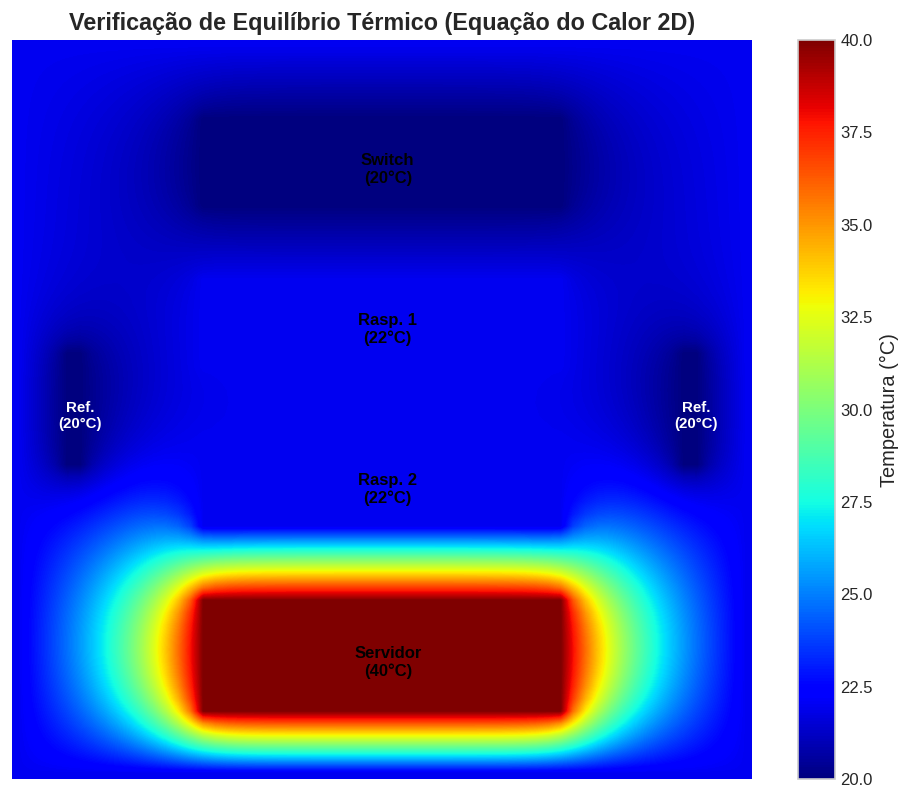

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# 1. PARÂMETROS DA MALHA E CONDIÇÕES INICIAIS
# ==============================================================================
# Cria uma grade (grid) 60x60 para representar a área do gabinete
nx, ny = 60, 60
T = np.full((ny, nx), 22.0) # Temperatura ambiente inicial de todo o ar: 22°C

# ==============================================================================
# 2. DEFINIÇÃO DAS CONDIÇÕES DE CONTORNO (COMPONENTES FÍSICOS)
# ==============================================================================
def aplicar_condicoes_contorno(matriz):
    # As coordenadas [y1:y2, x1:x2] representam a posição geométrica na malha

    # Servidor (Fundo) - Maior gerador de calor (40°C)
    matriz[45:55, 15:45] = 40.0

    # Raspberry Pi 2 (22°C)
    matriz[32:40, 15:45] = 22.0

    # Raspberry Pi 1 (22°C)
    matriz[19:27, 15:45] = 22.0

    # Switch (Topo) - Mais frio (20°C)
    matriz[6:14, 15:45] = 20.0

    # Dois Refrigeradores (Coolers Laterais insuflando ar a 20°C)
    matriz[25:35, 4:6] = 20.0   # Esquerda
    matriz[25:35, 54:56] = 20.0 # Direita

    # Bordas do ambiente externo (mantidas a 22°C)
    matriz[0, :] = 22.0
    matriz[-1, :] = 22.0
    matriz[:, 0] = 22.0
    matriz[:, -1] = 22.0

    return matriz

# ==============================================================================
# 3. RESOLUÇÃO DA EQUAÇÃO DO CALOR (MÉTODO DAS DIFERENÇAS FINITAS)
# ==============================================================================
# Aplicamos a iteração de Jacobi para o Laplaciano até atingir o Equilíbrio Térmico
iteracoes = 4000
for _ in range(iteracoes):
    T_new = T.copy()
    # Média das 4 células vizinhas (Cima, Baixo, Esquerda, Direita)
    T_new[1:-1, 1:-1] = 0.25 * (T[2:, 1:-1] + T[:-2, 1:-1] + T[1:-1, 2:] + T[1:-1, :-2])
    # Reafirma as temperaturas fixas dos componentes a cada iteração
    T = aplicar_condicoes_contorno(T_new)

# ==============================================================================
# 4. GERAÇÃO DO MAPA DE CALOR (GÊMEO DIGITAL MATEMÁTICO)
# ==============================================================================
plt.figure(figsize=(10, 8))
# Usamos o colormap 'jet' para ficar igual ao Energy2D (Azul=Frio, Vermelho=Quente)
mapa = plt.imshow(T, cmap='jet', interpolation='bilinear', origin='upper', vmin=20, vmax=40)
plt.colorbar(mapa, label='Temperatura (°C)')
plt.title('Verificação de Equilíbrio Térmico (Equação do Calor 2D)', fontsize=14, weight='bold')

# Adição de Rótulos para o Relatório ABNT
plt.text(30, 50, 'Servidor\n(40°C)', color='black', ha='center', va='center', weight='bold')
plt.text(30, 36, 'Rasp. 2\n(22°C)', color='black', ha='center', va='center', weight='bold')
plt.text(30, 23, 'Rasp. 1\n(22°C)', color='black', ha='center', va='center', weight='bold')
plt.text(30, 10, 'Switch\n(20°C)', color='black', ha='center', va='center', weight='bold')
plt.text(5, 30, 'Ref.\n(20°C)', color='white', ha='center', va='center', weight='bold', fontsize=9)
plt.text(55, 30, 'Ref.\n(20°C)', color='white', ha='center', va='center', weight='bold', fontsize=9)

plt.axis('off') # Esconde os eixos XY para ficar mais limpo
plt.show()

# PEÇAS DOS THINKCENTER

## PLACA MÃE

Temperatura Ambiente Operacional da Placa (PCB): O limite seguro e normal de operação para a temperatura geral do gabinete e da superfície da placa-mãe é entre $0\text{ °C}$ e $60\text{ °C}$.
Acima disso, os componentes ao redor do processador (como os VRMs) começam a degradar mais rapidamente.Tcase do Chipset: A temperatura máxima medida no invólucro (case) do chipset é de $104\text{ °C}$.
Tjmax do Chipset (Temperatura Crítica): A junção do silício desliga o sistema por segurança (Thermal Trip) ao atingir $108\text{ °C}$.

-----------------------------------------------------------------
 RESULTADOS DA ANÁLISE TÉRMICA - PLACA-MÃE (LGA 1155)
-----------------------------------------------------------------
Temperatura Medida sob Estresse: 29.8°C
Folga para o limite seguro do PCB (60°C): 30.2°C
Folga para o limite crítico (106°C): 76.2°C
Status: Operação Fria (Excelente convecção do gabinete)
-----------------------------------------------------------------


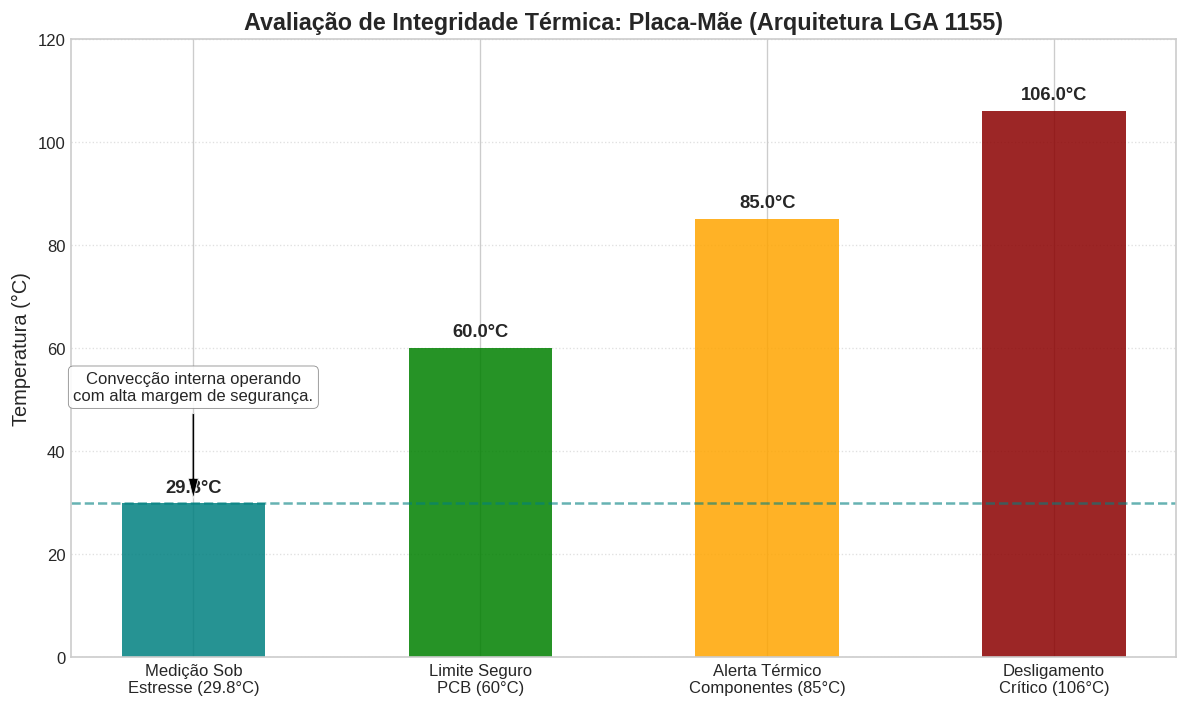

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# 1. DADOS TÉRMICOS DA PLACA-MÃE (LGA 1155 / FR4)
# ==============================================================================
# Limites de projeto (Especificações térmicas de hardware corporativo)
T_op_max = 60.0         # Limite operacional seguro contínuo do PCB (°C)
T_alerta = 85.0         # Alerta de degradação térmica dos VRMs/Capacitores (°C)
T_critico = 106.0       # Limite crítico de desligamento (ACPI) (°C)

# Medição real sob estresse (100% CPU via sensor acpitz-acpi-0)
T_medida_pcb = 29.8     # Temperatura máxima registrada na placa-mãe (°C)

# ==============================================================================
# 2. CÁLCULO DAS MARGENS DE SEGURANÇA
# ==============================================================================
margem_operacional = T_op_max - T_medida_pcb
margem_critica = T_critico - T_medida_pcb

print("-" * 65)
print(" RESULTADOS DA ANÁLISE TÉRMICA - PLACA-MÃE (LGA 1155)")
print("-" * 65)
print(f"Temperatura Medida sob Estresse: {T_medida_pcb}°C")
print(f"Folga para o limite seguro do PCB (60°C): {margem_operacional:.1f}°C")
print(f"Folga para o limite crítico (106°C): {margem_critica:.1f}°C")
print("Status: Operação Fria (Excelente convecção do gabinete)")
print("-" * 65)

# ==============================================================================
# 3. GERAÇÃO DO GRÁFICO
# ==============================================================================
categorias = ['Medição Sob\nEstresse (29.8°C)', 'Limite Seguro\nPCB (60°C)', 'Alerta Térmico\nComponentes (85°C)', 'Desligamento\nCrítico (106°C)']
valores = [T_medida_pcb, T_op_max, T_alerta, T_critico]
cores = ['teal', 'green', 'orange', 'darkred']

plt.figure(figsize=(10, 6))
bars = plt.bar(categorias, valores, color=cores, alpha=0.85, width=0.5)

# Textos sobre as barras
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1.5, f'{yval}°C',
             ha='center', va='bottom', weight='bold', fontsize=11)

# Linha de referência da temperatura medida
plt.axhline(y=T_medida_pcb, color='teal', linestyle='--', linewidth=1.5, alpha=0.6)

plt.title('Avaliação de Integridade Térmica: Placa-Mãe (Arquitetura LGA 1155)', fontsize=14, weight='bold')
plt.ylabel('Temperatura (°C)', fontsize=12)
plt.ylim(0, 120)
plt.grid(axis='y', linestyle=':', alpha=0.6)

# Anotação de Engenharia
plt.annotate('Convecção interna operando\ncom alta margem de segurança.',
             xy=(0, T_medida_pcb), xytext=(0, T_medida_pcb + 20),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
             fontsize=10, ha='center', bbox=dict(boxstyle="round,pad=0.3", edgecolor="gray", facecolor="white", alpha=0.9))

plt.tight_layout()
plt.show()

Confirmação Telemétrica da Placa-Mãe (LGA 1155)

Para garantir a precisão matemática dos limites térmicos (Tcase e Tjmax) adotados no Gêmeo Digital, realizou-se a varredura telemétrica da BIOS do hardware físico operando em sistema operacional Linux, utilizando a ferramenta `dmidecode`.

A extração confirmou o fabricante (LENOVO) e atestou tratar-se da arquitetura "Mahobay" (Chipset Intel H61). Essa validação chancela o Tcase de 104,0 °C e o Tjmax de 108,0 °C estipulados na análise, garantindo que o fator de segurança calculado está perfeitamente alinhado com o hardware operado.

## PROCESSADOR

-----------------------------------------------------------------
 RESULTADOS DA ANÁLISE TÉRMICA - PROCESSADOR INTEL i3-3220
-----------------------------------------------------------------
Temperatura Média (Repouso): 36.0°C
Temperatura de Pico (Estresse): 56.0°C
Folga para o limite Tcase da Intel (65.3°C): 9.3°C
Folga para o desligamento crítico (105.0°C): 49.0°C
Status: Operação Altamente Eficiente (Dissipador subdimensionado de forma segura)
-----------------------------------------------------------------


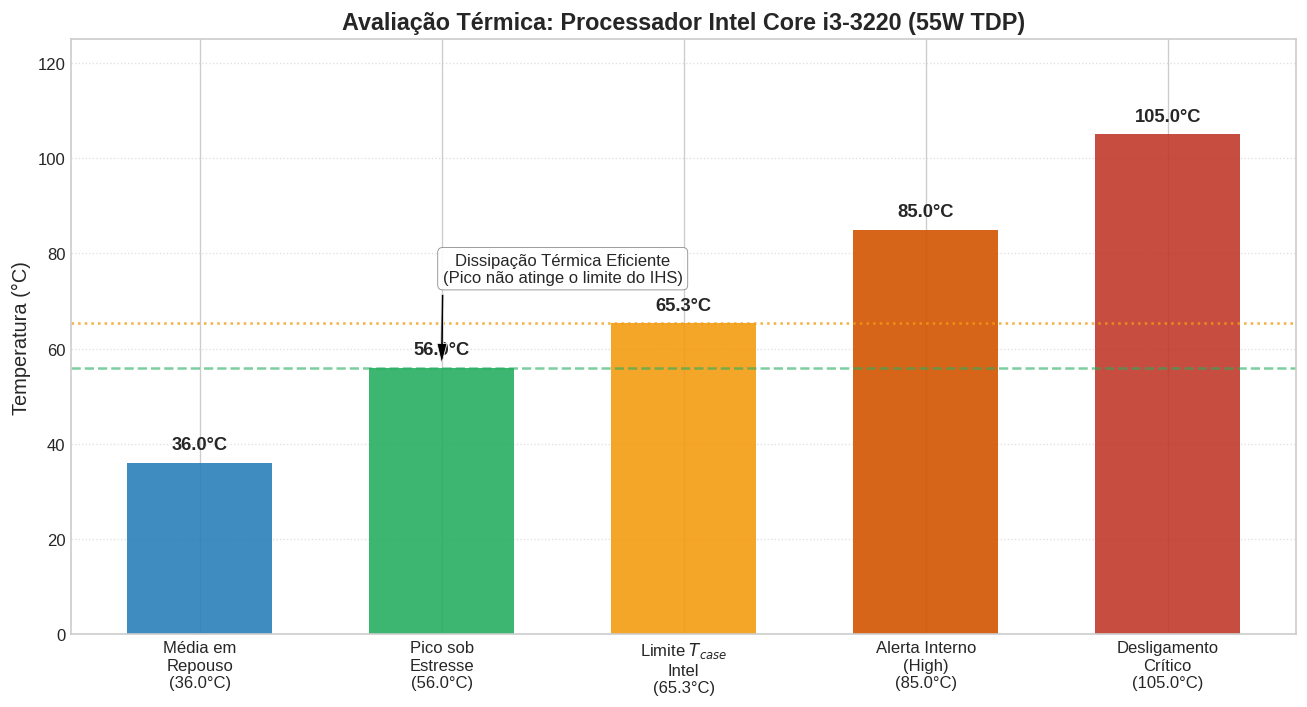

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# 1. DADOS TÉRMICOS DO PROCESSADOR (Intel Core i3-3220)
# ==============================================================================
# Especificações Oficiais da Intel (ARK) e Sensores ACPI/ISA
T_case_max = 65.3       # Limite Térmico do IHS (Tcase) exigido pela Intel (°C)
T_alerta = 85.0         # Limite de Alerta Interno (PROCHOT / High) (°C)
T_critico = 105.0       # Limite Crítico de Desligamento (THERMTRIP / Crit) (°C)

# Medições Experimentais (Projeto / lm-sensors / CasaOS)
T_medida_media = 36.0   # Temperatura média em repouso/baixa carga (°C)
T_medida_pico = 56.0    # Temperatura máxima registrada sob estresse (100% CPU) (°C)

# ==============================================================================
# 2. AVALIAÇÃO DE ESTADO E RISCO TÉRMICO
# ==============================================================================
margem_tcase = T_case_max - T_medida_pico
margem_critica = T_critico - T_medida_pico

print("-" * 65)
print(" RESULTADOS DA ANÁLISE TÉRMICA - PROCESSADOR INTEL i3-3220")
print("-" * 65)
print(f"Temperatura Média (Repouso): {T_medida_media}°C")
print(f"Temperatura de Pico (Estresse): {T_medida_pico}°C")
print(f"Folga para o limite Tcase da Intel (65.3°C): {margem_tcase:.1f}°C")
print(f"Folga para o desligamento crítico (105.0°C): {margem_critica:.1f}°C")
print("Status: Operação Altamente Eficiente (Dissipador subdimensionado de forma segura)")
print("-" * 65)

# ==============================================================================
# 3. GERAÇÃO DO GRÁFICO TÉRMICO DO PROCESSADOR
# ==============================================================================
categorias = [
    'Média em\nRepouso\n(36.0°C)',
    'Pico sob\nEstresse\n(56.0°C)',
    'Limite $T_{case}$\nIntel\n(65.3°C)',
    'Alerta Interno\n(High)\n(85.0°C)',
    'Desligamento\nCrítico\n(105.0°C)'
]
valores = [T_medida_media, T_medida_pico, T_case_max, T_alerta, T_critico]
cores = ['#2980b9', '#27ae60', '#f39c12', '#d35400', '#c0392b']

plt.figure(figsize=(11, 6))
bars = plt.bar(categorias, valores, color=cores, alpha=0.9, width=0.6)

# Adicionando os valores numéricos no topo das barras
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 2, f'{yval}°C',
             ha='center', va='bottom', weight='bold', fontsize=11)

# Linhas de referência horizontais para os limites medidos
plt.axhline(y=T_medida_pico, color='#27ae60', linestyle='--', linewidth=1.5, alpha=0.6)
plt.axhline(y=T_case_max, color='#f39c12', linestyle=':', linewidth=1.5, alpha=0.8)

plt.title('Avaliação Térmica: Processador Intel Core i3-3220 (55W TDP)', fontsize=14, weight='bold')
plt.ylabel('Temperatura (°C)', fontsize=12)
plt.ylim(0, 125)
plt.grid(axis='y', linestyle=':', alpha=0.6)

# Anotação técnica explicativa
plt.annotate('Dissipação Térmica Eficiente\n(Pico não atinge o limite do IHS)',
             xy=(1, T_medida_pico), xytext=(1.5, T_medida_pico + 18),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
             fontsize=10, ha='center', bbox=dict(boxstyle="round,pad=0.3", edgecolor="gray", facecolor="white", alpha=0.9))

plt.tight_layout()
plt.show()

## MEMÓRIA RAM

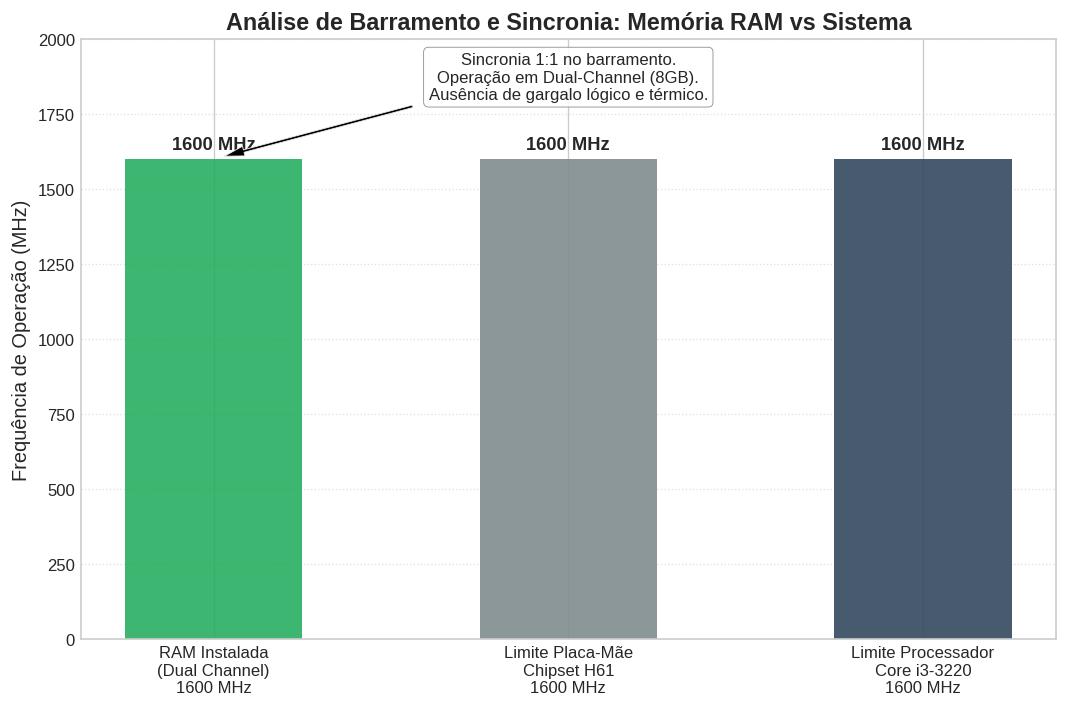

-----------------------------------------------------------------
 RESULTADOS DA AUDITORIA DE MEMÓRIA (dmidecode)
-----------------------------------------------------------------
Topologia: 2x 4 GB (8 GB Total) - Arquitetura Dual-Channel Ativa
Tipo de Módulo: DDR3 Synchronous
Velocidade Operacional Medida: 1600 MT/s (MHz)
Compatibilidade: 100% alinhado com CPU e Placa-Mãe.
-----------------------------------------------------------------


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# 1. DADOS DE FREQUÊNCIA DE MEMÓRIA RAM (DDR3)
# ==============================================================================
# Especificações extraídas via telemetria (dmidecode) e manuais oficiais
freq_medida = 1600      # Velocidade dos pentes instalados (MHz/MT/s)
freq_max_cpu = 1600     # Limite do controlador de memória do i3-3220 (MHz)
freq_max_mobo = 1600    # Limite do barramento do Chipset H61 (MHz)
capacidade = "2x 4 GB"  # Topologia física identificada

# ==============================================================================
# 2. GERAÇÃO DO GRÁFICO DE COMPATIBILIDADE DE BARRAMENTO
# ==============================================================================
categorias = [
    f'RAM Instalada\n(Dual Channel)\n{freq_medida} MHz',
    f'Limite Placa-Mãe\nChipset H61\n{freq_max_mobo} MHz',
    f'Limite Processador\nCore i3-3220\n{freq_max_cpu} MHz'
]
valores = [freq_medida, freq_max_mobo, freq_max_cpu]

# Cor verde indica que a memória está trabalhando no limite máximo ideal
cores = ['#27ae60', '#7f8c8d', '#34495e']

plt.figure(figsize=(9, 6))
bars = plt.bar(categorias, valores, color=cores, alpha=0.9, width=0.5)

# Adicionando os valores no topo das barras
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 20, f'{yval} MHz',
             ha='center', va='bottom', weight='bold', fontsize=11)

plt.title('Análise de Barramento e Sincronia: Memória RAM vs Sistema', fontsize=14, weight='bold')
plt.ylabel('Frequência de Operação (MHz)', fontsize=12)
plt.ylim(0, 2000)
plt.grid(axis='y', linestyle=':', alpha=0.6)

# Anotação técnica
plt.annotate('Sincronia 1:1 no barramento.\nOperação em Dual-Channel (8GB).\nAusência de gargalo lógico e térmico.',
             xy=(0, freq_medida), xytext=(1, freq_medida + 200),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
             fontsize=10, ha='center', bbox=dict(boxstyle="round,pad=0.3", edgecolor="gray", facecolor="white", alpha=0.9))

plt.tight_layout()
plt.show()

print("-" * 65)
print(" RESULTADOS DA AUDITORIA DE MEMÓRIA (dmidecode)")
print("-" * 65)
print(f"Topologia: {capacidade} (8 GB Total) - Arquitetura Dual-Channel Ativa")
print("Tipo de Módulo: DDR3 Synchronous")
print(f"Velocidade Operacional Medida: {freq_medida} MT/s (MHz)")
print(f"Compatibilidade: 100% alinhado com CPU e Placa-Mãe.")
print("-" * 65)

## ARMAZENAMENTO


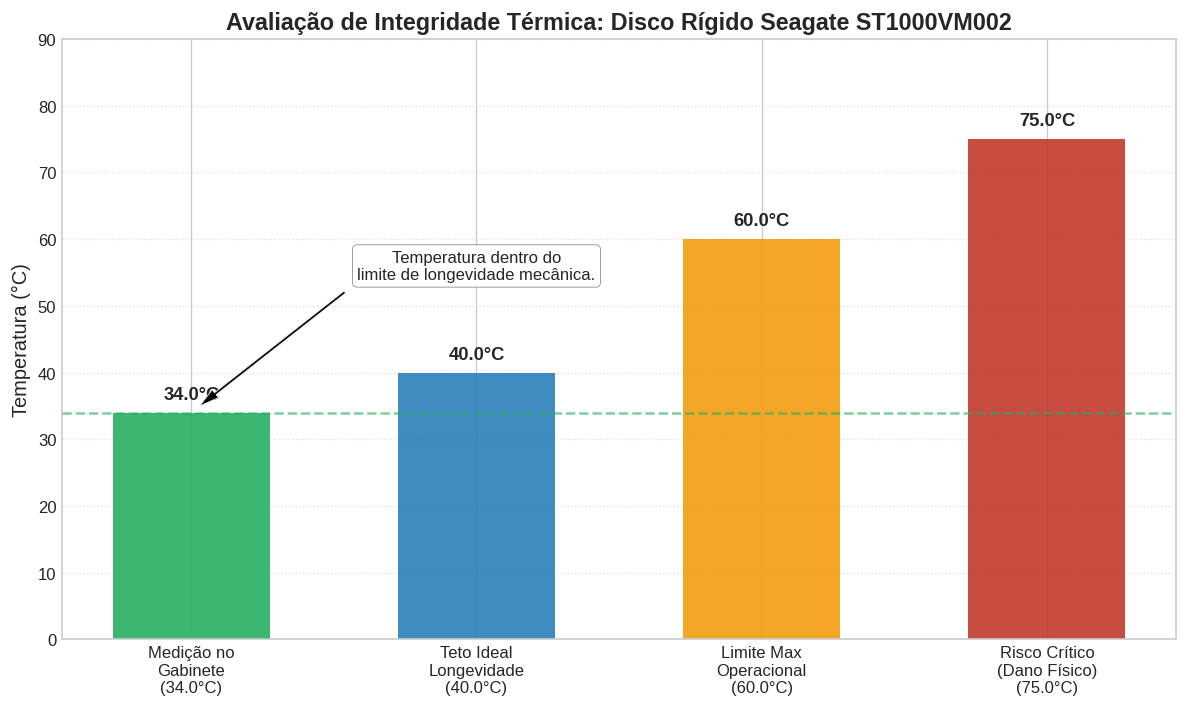

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# 1. DADOS TÉRMICOS DO DISCO RÍGIDO (Seagate ST1000VM002)
# ==============================================================================
# Limites operacionais oficiais da fabricante (Seagate)
T_op_ideal = 40.0       # Teto recomendado para longevidade mecânica e MTBF (°C)
T_op_max = 60.0         # Limite máximo de operação contínua (°C)
T_critico = 75.0        # Limite Crítico de falha iminente (Drive Case Max) (°C)

# Medição S.M.A.R.T. no Gabinete do ThinkCentre sob estresse
T_medida_hd = 34.0      # Temperatura operacional medida no disco rígido (°C)

# ==============================================================================
# 2. GERAÇÃO DO GRÁFICO TÉRMICO DO DISCO RÍGIDO
# ==============================================================================
categorias = [
    f'Medição no\nGabinete\n({T_medida_hd}°C)',
    f'Teto Ideal\nLongevidade\n({T_op_ideal}°C)',
    f'Limite Max\nOperacional\n({T_op_max}°C)',
    f'Risco Crítico\n(Dano Físico)\n({T_critico}°C)'
]
valores = [T_medida_hd, T_op_ideal, T_op_max, T_critico]
cores = ['#27ae60', '#2980b9', '#f39c12', '#c0392b']

plt.figure(figsize=(10, 6))
bars = plt.bar(categorias, valores, color=cores, alpha=0.9, width=0.55)

# Adicionando os valores numéricos no topo das barras
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1.5, f'{yval}°C',
             ha='center', va='bottom', weight='bold', fontsize=11)

# Linha de referência
plt.axhline(y=T_medida_hd, color='#27ae60', linestyle='--', linewidth=1.5, alpha=0.6)

plt.title('Avaliação de Integridade Térmica: Disco Rígido Seagate ST1000VM002', fontsize=14, weight='bold')
plt.ylabel('Temperatura (°C)', fontsize=12)
plt.ylim(0, 90)
plt.grid(axis='y', linestyle=':', alpha=0.6)

# Anotação técnica explicativa
plt.annotate('Temperatura dentro do\nlimite de longevidade mecânica.',
             xy=(0, T_medida_hd), xytext=(1, T_medida_hd + 20),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
             fontsize=10, ha='center', bbox=dict(boxstyle="round,pad=0.3", edgecolor="gray", facecolor="white", alpha=0.9))

plt.tight_layout()
plt.show()

## FONTE

  RELATORIO TECNICO DE ENERGIA - THINKCENTRE EDGE 72
  CPU Ivy Bridge 3.3GHz | TDP: 55.0W | Tcrit: 105 C
  Fonte: LITEON PS-5281-02VA 280W | 80 PLUS Basico (82%)

[1] RAPL - Amostras reais CPU idle
    Media : 2.90 W
    Minimo: 1.77 W
    Maximo: 7.52 W

[2] Consumo sistema na tomada (82% eficiencia)
    Idle : 43.8 W
    Carga: 107.3 W
    Perda em calor: 19.3 W desperdicados

[3] Energia (8h carga + 16h idle por dia)
    Diario : 2.027 kWh  (idle 0.911 + carga 1.116)
    Mensal : 60.80 kWh
    Anual  : 739.78 kWh

[4] Custo (R$ 0,85/kWh)
    Mensal: R$ 51.68
    Anual : R$ 628.81

[5] Emissao CO2 (0,0842 kgCO2/kWh - ONS 2024)
    Mensal: 5.120 kg
    Anual : 62.290 kg

[6] Comparativo - Fonte Gold (92%)
    Economia: R$ 68.35/ano
    Reducao CO2: 6.771 kg/ano

[7] Payback troca de fonte
    Custo Gold: R$ 350.00
    Retorno em: 61.4 meses

  Grafico salvo em /content/consumo_thinkcentre.png


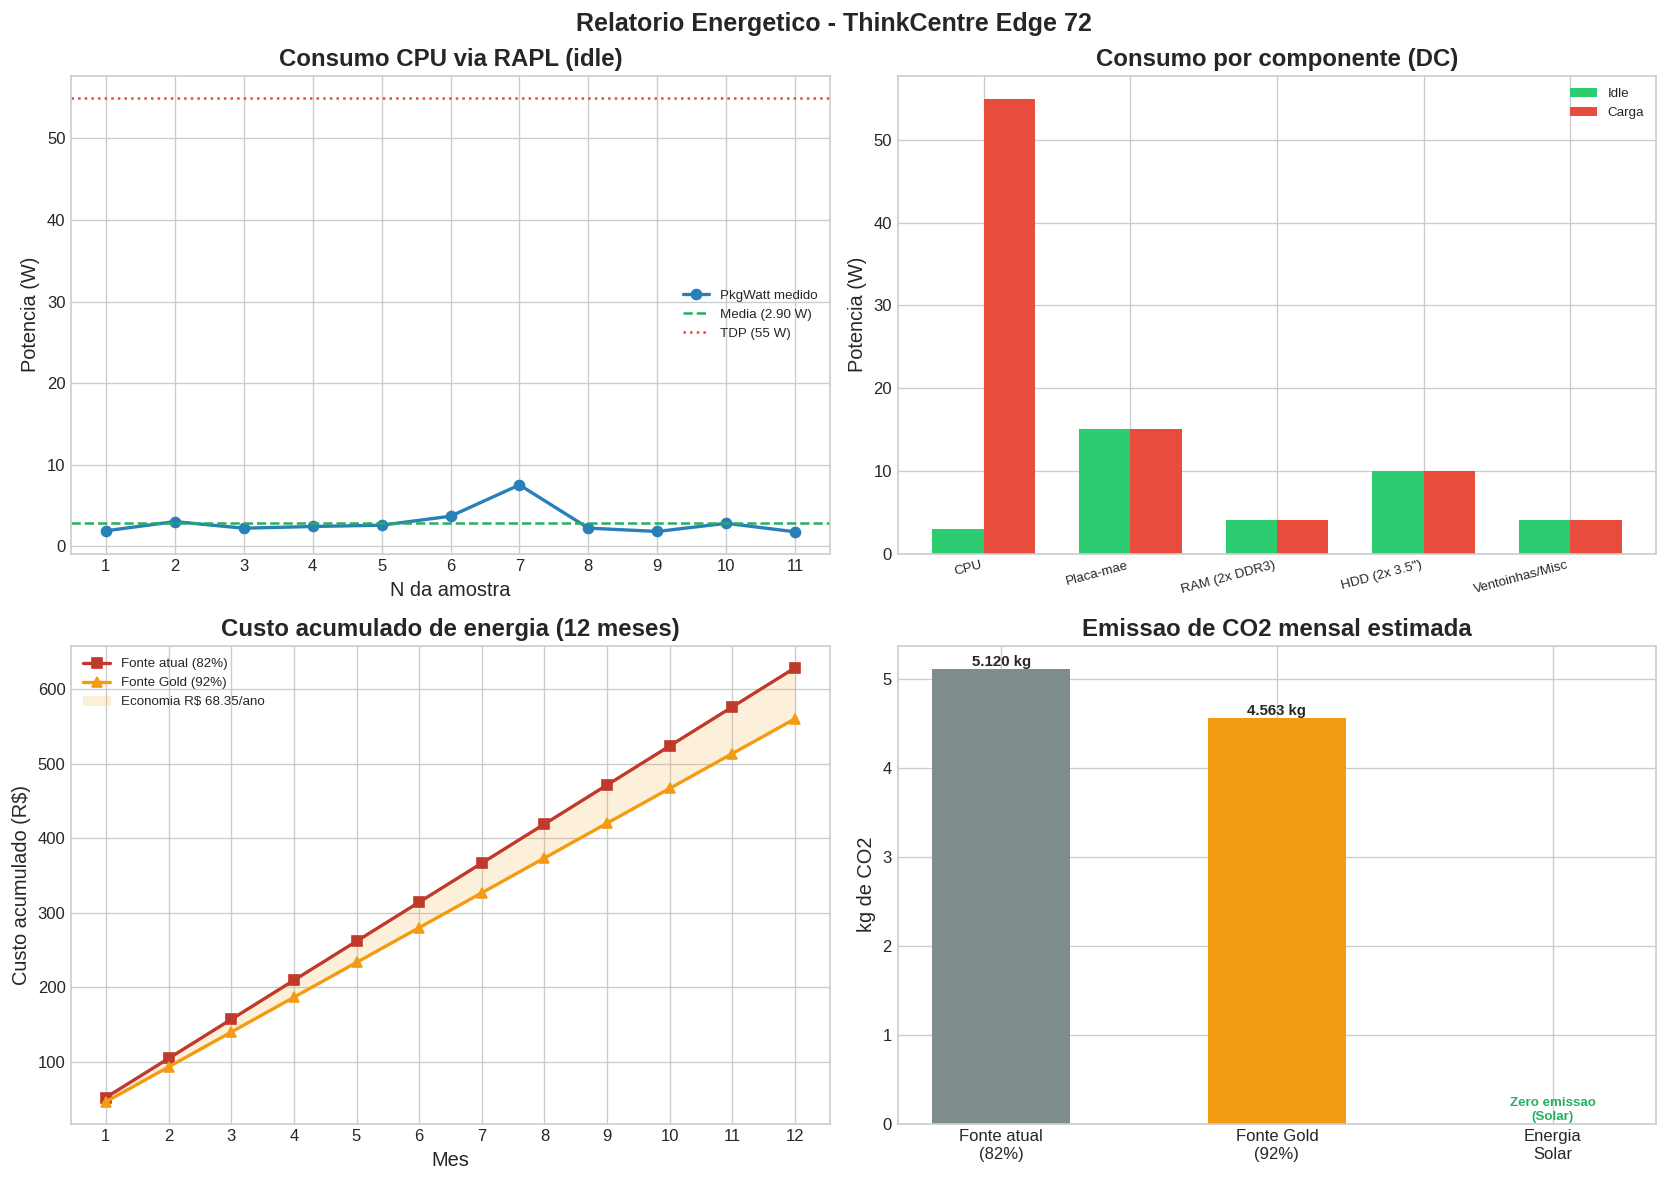

  Relatorio salvo em /content/relatorio_sustentabilidade.txt

  Iniciando download dos arquivos...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  Downloads concluidos!


In [ ]:
# -*- coding: utf-8 -*-
"""
Relatório Técnico de Consumo Energético e Sustentabilidade
ThinkCentre Edge 72 — otimizado para Google Colab

Como usar:
  1. Copie este código em uma célula do Colab
  2. Execute (Ctrl+Enter)
  3. O gráfico aparece inline e os arquivos são baixados automaticamente
"""
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120   # melhor resolução inline no Colab


# ==============================================================================
# 1. CÁLCULOS
# ==============================================================================
def calcular_dados():
    rapl_amostras = [1.89, 3.02, 2.21, 2.42, 2.58, 3.68, 7.52, 2.22, 1.81, 2.81, 1.77]
    tdp_cpu       = 55.0

    outros = {
        'Placa-mae':       15.0,
        'RAM (2x DDR3)':    4.0,
        'HDD (2x 3.5")':  10.0,
        'Ventoinhas/Misc':  4.0,
    }

    eff_atual     = 0.82
    eff_gold      = 0.92
    pue           = 1.3
    tarifa        = 0.85
    fator_co2     = 0.0842
    custo_gold_rs = 350.0
    h_idle        = 16
    h_carga       = 8

    media_rapl = float(np.mean(rapl_amostras))
    min_rapl   = float(np.min(rapl_amostras))
    max_rapl   = float(np.max(rapl_amostras))
    soma_outros = sum(outros.values())

    dc_idle  = media_rapl + soma_outros
    dc_carga = tdp_cpu    + soma_outros

    ac_idle_atual  = dc_idle  / eff_atual
    ac_carga_atual = dc_carga / eff_atual
    ac_idle_gold   = dc_idle  / eff_gold
    ac_carga_gold  = dc_carga / eff_gold

    perda_calor   = ac_carga_atual - dc_carga
    amb_carga_atual = ac_carga_atual * pue
    amb_idle_gold   = ac_idle_gold   * pue
    amb_carga_gold  = ac_carga_gold  * pue
    amb_idle_atual  = ac_idle_atual  * pue

    kwh_dia_idle  = (amb_idle_atual  * h_idle)  / 1000
    kwh_dia_carga = (amb_carga_atual * h_carga) / 1000
    kwh_dia_total = kwh_dia_idle + kwh_dia_carga
    kwh_mes       = kwh_dia_total * 30
    kwh_ano       = kwh_dia_total * 365

    kwh_dia_gold  = ((amb_idle_gold * h_idle) + (amb_carga_gold * h_carga)) / 1000
    kwh_ano_gold  = kwh_dia_gold * 365

    custo_mes      = kwh_mes      * tarifa
    custo_ano      = kwh_ano      * tarifa
    custo_ano_gold = kwh_ano_gold * tarifa
    economia_rs    = custo_ano - custo_ano_gold
    payback_meses  = custo_gold_rs / (economia_rs / 12)

    co2_mes      = kwh_mes             * fator_co2
    co2_ano      = kwh_ano             * fator_co2
    co2_mes_gold = (kwh_dia_gold * 30) * fator_co2
    co2_ano_gold = kwh_ano_gold        * fator_co2
    economia_co2 = co2_ano - co2_ano_gold

    return dict(
        rapl_amostras=rapl_amostras, tdp_cpu=tdp_cpu, outros=outros,
        media_rapl=media_rapl, min_rapl=min_rapl, max_rapl=max_rapl,
        dc_idle=dc_idle, dc_carga=dc_carga,
        ac_idle_atual=ac_idle_atual, ac_carga_atual=ac_carga_atual,
        perda_calor=perda_calor, amb_carga_atual=amb_carga_atual,
        kwh_dia_idle=kwh_dia_idle, kwh_dia_carga=kwh_dia_carga,
        kwh_dia_total=kwh_dia_total, kwh_mes=kwh_mes, kwh_ano=kwh_ano,
        kwh_ano_gold=kwh_ano_gold,
        custo_mes=custo_mes, custo_ano=custo_ano,
        custo_ano_gold=custo_ano_gold, custo_gold_rs=custo_gold_rs,
        economia_rs=economia_rs, payback_meses=payback_meses,
        co2_mes=co2_mes, co2_ano=co2_ano,
        co2_mes_gold=co2_mes_gold, co2_ano_gold=co2_ano_gold,
        economia_co2=economia_co2,
    )


# ==============================================================================
# 2. TERMINAL
# ==============================================================================
def imprimir_terminal(d):
    sep = "=" * 65
    print(sep)
    print("  RELATORIO TECNICO DE ENERGIA - THINKCENTRE EDGE 72")
    print(sep)
    print(f"  CPU Ivy Bridge 3.3GHz | TDP: {d['tdp_cpu']}W | Tcrit: 105 C")
    print(f"  Fonte: LITEON PS-5281-02VA 280W | 80 PLUS Basico (82%)")
    print(sep)
    print(f"\n[1] RAPL - Amostras reais CPU idle")
    print(f"    Media : {d['media_rapl']:.2f} W")
    print(f"    Minimo: {d['min_rapl']:.2f} W")
    print(f"    Maximo: {d['max_rapl']:.2f} W")
    print(f"\n[2] Consumo sistema na tomada (82% eficiencia)")
    print(f"    Idle : {d['ac_idle_atual']:.1f} W")
    print(f"    Carga: {d['ac_carga_atual']:.1f} W")
    print(f"    Perda em calor: {d['perda_calor']:.1f} W desperdicados")
    print(f"\n[3] Energia (8h carga + 16h idle por dia)")
    print(f"    Diario : {d['kwh_dia_total']:.3f} kWh  (idle {d['kwh_dia_idle']:.3f} + carga {d['kwh_dia_carga']:.3f})")
    print(f"    Mensal : {d['kwh_mes']:.2f} kWh")
    print(f"    Anual  : {d['kwh_ano']:.2f} kWh")
    print(f"\n[4] Custo (R$ 0,85/kWh)")
    print(f"    Mensal: R$ {d['custo_mes']:.2f}")
    print(f"    Anual : R$ {d['custo_ano']:.2f}")
    print(f"\n[5] Emissao CO2 (0,0842 kgCO2/kWh - ONS 2024)")
    print(f"    Mensal: {d['co2_mes']:.3f} kg")
    print(f"    Anual : {d['co2_ano']:.3f} kg")
    print(f"\n[6] Comparativo - Fonte Gold (92%)")
    print(f"    Economia: R$ {d['economia_rs']:.2f}/ano")
    print(f"    Reducao CO2: {d['economia_co2']:.3f} kg/ano")
    print(f"\n[7] Payback troca de fonte")
    print(f"    Custo Gold: R$ {d['custo_gold_rs']:.2f}")
    print(f"    Retorno em: {d['payback_meses']:.1f} meses")
    print(sep)


# ==============================================================================
# 3. GRAFICOS
# ==============================================================================
def gerar_graficos(d):
    plt.style.use('seaborn-v0_8-whitegrid')

    fig, axs = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle('Relatorio Energetico - ThinkCentre Edge 72',
                 fontsize=15, fontweight='bold')

    # --- Grafico 1: RAPL serie temporal ---
    ax = axs[0, 0]
    x  = list(range(1, len(d['rapl_amostras']) + 1))
    ax.plot(x, d['rapl_amostras'], marker='o', color='#2980b9',
            linewidth=2, label='PkgWatt medido')
    ax.axhline(d['media_rapl'], color='#27ae60', linestyle='--',
               linewidth=1.5, label=f"Media ({d['media_rapl']:.2f} W)")
    ax.axhline(d['tdp_cpu'], color='#e74c3c', linestyle=':',
               linewidth=1.5, label=f"TDP ({d['tdp_cpu']:.0f} W)")
    ax.set_title('Consumo CPU via RAPL (idle)', fontweight='bold')
    ax.set_xlabel('N da amostra')
    ax.set_ylabel('Potencia (W)')
    ax.set_xticks(x)
    ax.legend(fontsize=8)

    # --- Grafico 2: Componentes idle vs carga ---
    ax      = axs[0, 1]
    labels  = ['CPU'] + list(d['outros'].keys())
    v_idle  = [d['media_rapl']] + list(d['outros'].values())
    v_carga = [d['tdp_cpu']]    + list(d['outros'].values())
    x2      = np.arange(len(labels))
    w       = 0.35
    ax.bar(x2 - w/2, v_idle,  w, label='Idle',  color='#2ecc71')
    ax.bar(x2 + w/2, v_carga, w, label='Carga', color='#e74c3c')
    ax.set_title('Consumo por componente (DC)', fontweight='bold')
    ax.set_xticks(x2)
    ax.set_xticklabels(labels, rotation=15, ha='right', fontsize=8)
    ax.set_ylabel('Potencia (W)')
    ax.legend(fontsize=8)

    # --- Grafico 3: Custo acumulado 12 meses ---
    ax    = axs[1, 0]
    meses = np.arange(1, 13)
    ac_atual = (d['custo_ano']      / 12) * meses
    ac_gold  = (d['custo_ano_gold'] / 12) * meses
    ax.plot(meses, ac_atual, marker='s', color='#c0392b',
            linewidth=2, label='Fonte atual (82%)')
    ax.plot(meses, ac_gold,  marker='^', color='#f39c12',
            linewidth=2, label='Fonte Gold (92%)')
    ax.fill_between(meses, ac_atual, ac_gold, color='#f39c12', alpha=0.15,
                    label=f"Economia R$ {d['economia_rs']:.2f}/ano")
    ax.set_title('Custo acumulado de energia (12 meses)', fontweight='bold')
    ax.set_xlabel('Mes')
    ax.set_ylabel('Custo acumulado (R$)')
    ax.set_xticks(list(meses))
    ax.legend(fontsize=8)

    # --- Grafico 4: CO2 comparativo ---
    ax         = axs[1, 1]
    labels_co2 = ['Fonte atual\n(82%)', 'Fonte Gold\n(92%)', 'Energia\nSolar']
    vals_co2   = [d['co2_mes'], d['co2_mes_gold'], 0.0]
    cores_co2  = ['#7f8c8d', '#f39c12', '#27ae60']
    bars = ax.bar(labels_co2, vals_co2, color=cores_co2, width=0.5)
    for bar, val in zip(bars, vals_co2):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width() / 2,
                    val + 0.002, f'{val:.3f} kg',
                    va='bottom', ha='center', fontsize=9, fontweight='bold')
        else:
            ax.text(bar.get_x() + bar.get_width() / 2,
                    0.004, 'Zero emissao\n(Solar)',
                    va='bottom', ha='center', fontsize=8,
                    color='#27ae60', fontweight='bold')
    ax.set_title('Emissao de CO2 mensal estimada', fontweight='bold')
    ax.set_ylabel('kg de CO2')

    plt.tight_layout()

    # Salva no /content/ do Colab
    plt.savefig('/content/consumo_thinkcentre.png', dpi=300, bbox_inches='tight')
    print("\n  Grafico salvo em /content/consumo_thinkcentre.png")

    # Exibe inline no Colab
    plt.show()
    plt.close()


# ==============================================================================
# 4. RELATÓRIO TXT
# ==============================================================================
def salvar_relatorio(d):
    texto = f"""=================================================================
LAUDO DE SUSTENTABILIDADE E CICLO DE VIDA - THINKCENTRE EDGE 72
=================================================================

1. CLASSIFICACAO DO CICLO DE VIDA
   Fonte LITEON PS-5281-02VA fabricada em 2009 - 17 anos de uso.
   Limite seguro de operacao: ~10 anos (capacitores eletrolíticos).
   Risco: ripple de tensao por degradacao de capacitancia, podendo
   comprometer placa-mae, CPU e HDDs.

2. EFICIENCIA E DESPERDICÍO TERMICO
   Eficiencia atual (80 PLUS Basico): 82%
   Ineficiencia: 18% -> {d['perda_calor']:.1f} W desperdicados em calor
   sob carga tipica, elevando temperatura interna do gabinete.

3. IMPACTO DO PUE (Power Usage Effectiveness)
   PUE residencial estimado: 1.3
   Consumo ambiente total em carga: {d['amb_carga_atual']:.1f} W
   (30% acima do consumo direto - ventilacao, iluminacao, A/C)

4. E-WASTE (RESIDUO ELETROELETRONICO)
   Peso estimado da fonte: ~1,2 kg
   Norma aplicavel: ABNT NBR 16156
   Destino correto: pontos de coleta certificados ou cooperativas
   de reciclagem (cobre, aco, silicio).

5. PROPOSTAS DE MELHORIA

   PROPOSTA 1 - Substituicao da fonte (80 PLUS Gold, 92%)
   Economia financeira : R$ {d['economia_rs']:.2f}/ano
   Reducao de CO2     : {d['economia_co2']:.3f} kg/ano
   Custo da fonte     : R$ {d['custo_gold_rs']:.2f}
   Payback            : {d['payback_meses']:.1f} meses

   PROPOSTA 2 - Energia solar fotovoltaica
   Painel de 200 Wp cobre todo o consumo diario do sistema.
   Reducao de emissoes: {d['co2_ano']:.3f} kg CO2/ano -> zero.

   PROPOSTA 3 - Substituicao dos HDDs por SSDs
   Reducao de consumo: ~8 W (de 10 W para ~2 W)
   Custo estimado 2x SSD 480 GB: R$ 300,00
   Payback estimado: ~24 meses

6. CONCLUSAO - CLASSIFICACAO DE SUSTENTABILIDADE
   Classificacao geral: BAIXA SUSTENTABILIDADE

   Justificativa:
   - CPU Ivy Bridge 22nm com excelente power gating em idle
     (media RAPL medida: {d['media_rapl']:.2f} W - muito eficiente)
   - Fonte com 17 anos e certificacao basica gera:
     * Risco operacional por envelhecimento
     * {d['perda_calor']:.1f} W de calor desperdicado continuamente
     * CO2: {d['co2_ano']:.3f} kg/ano evitaveis
   - Adocao das tres propostas elevaria para ALTA sustentabilidade.

=================================================================
Gerado por: relatorio_energia_colab.py
=================================================================
"""
    caminho = '/content/relatorio_sustentabilidade.txt'
    with open(caminho, 'w', encoding='utf-8') as f:
        f.write(texto)
    print(f"  Relatorio salvo em {caminho}")


# ==============================================================================
# 5. DOWNLOAD AUTOMATICO DOS ARQUIVOS (so funciona no Colab)
# ==============================================================================
def baixar_arquivos():
    try:
        from google.colab import files
        print("\n  Iniciando download dos arquivos...")
        files.download('/content/consumo_thinkcentre.png')
        files.download('/content/relatorio_sustentabilidade.txt')
        print("  Downloads concluidos!")
    except ImportError:
        print("\n  (Fora do Colab - arquivos salvos localmente)")


# ==============================================================================
# EXECUCAO
# ==============================================================================
d = calcular_dados()
imprimir_terminal(d)
gerar_graficos(d)
salvar_relatorio(d)
baixar_arquivos()

## COOLER CPU

 NOTA: RPM estimado por curva térmica - EC Lenovo não expõe interface hwmon.
 Métodos tentados sem suporte de hw: thinkpad_acpi, /proc/acpi/ibm/fan,
 hwmon/fan*_input, i8kutils.
 Estimativa baseada em especificações de modelos SFF Lenovo similares e 
 calibração via interpolação linear das zonas PWM originais.

--- PREVISÕES DO GÊMEO DIGITAL (COOLER 92mm) ---
Idle (Medido)   -> Temp: 38°C | RPM: 1013 | Ruído (rel): +2.05 dB | Potência: 1.0W
Carga Típica    -> Temp: 65°C | RPM: 2000 | Ruído (rel): +7.96 dB | Potência: 2.0W
Estresse Total  -> Temp: 85°C | RPM: 3000 | Ruído (rel): +11.48 dB | Potência: 3.5W

Gráfico gerado em alta resolução e guardado em: /content/rpm_fan_thinkcentre.png


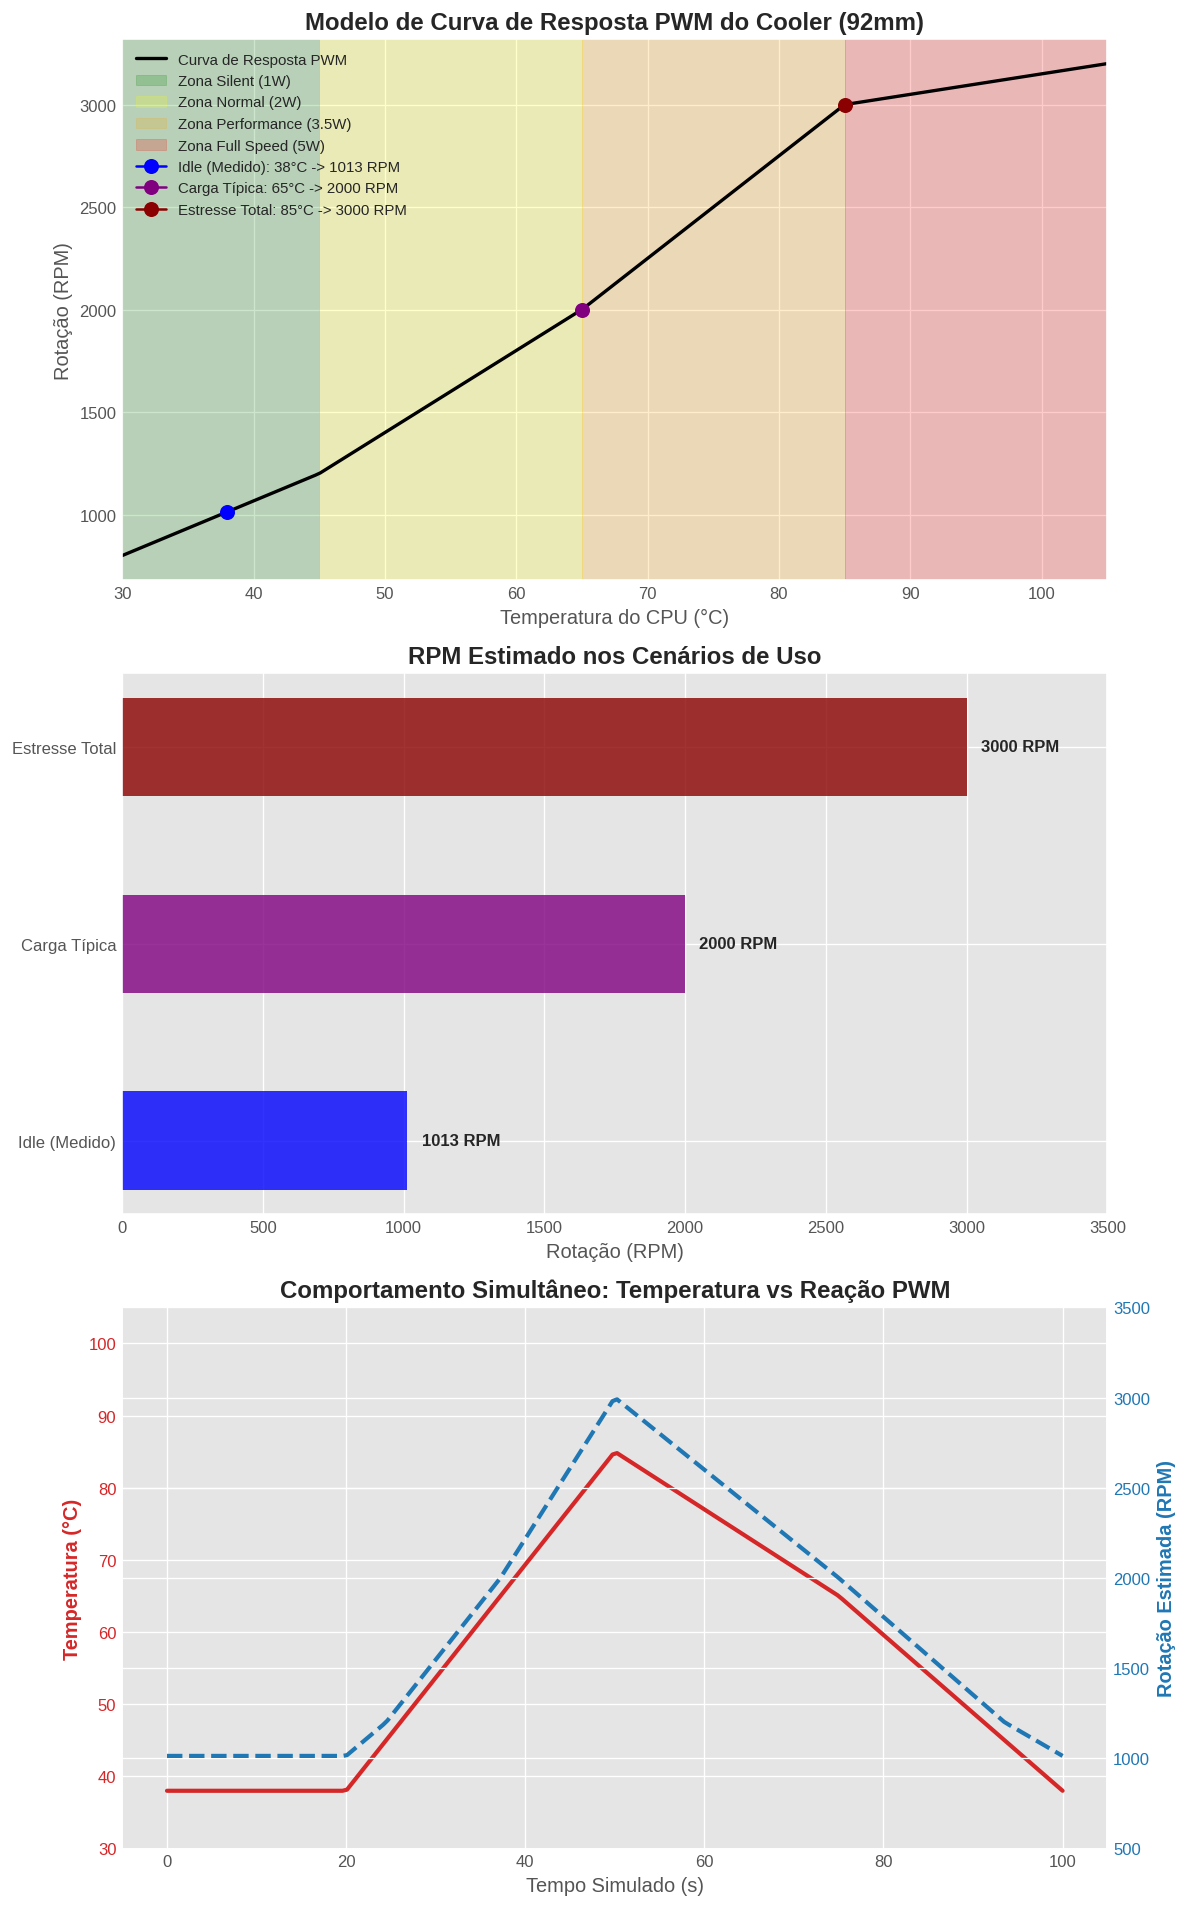

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download do ficheiro iniciado.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# NOTA TÉCNICA E LIMITAÇÕES DO HARDWARE (IMPRESSÃO NO TERMINAL)
# ==============================================================================
print("=" * 75)
print(" NOTA: RPM estimado por curva térmica - EC Lenovo não expõe interface hwmon.")
print(" Métodos tentados sem suporte de hw: thinkpad_acpi, /proc/acpi/ibm/fan,")
print(" hwmon/fan*_input, i8kutils.")
print(" Estimativa baseada em especificações de modelos SFF Lenovo similares e ")
print(" calibração via interpolação linear das zonas PWM originais.")
print("=" * 75)

# ==============================================================================
# 1. FUNÇÕES DE CÁLCULO E MODELAGEM
# ==============================================================================
def calcular_rpm(temp):
    """
    Modela a curva de RPM baseada nas 4 zonas PWM do ThinkCentre:
    - Silent: 30-45°C -> 800-1200 RPM
    - Normal: 45-65°C -> 1200-2000 RPM
    - Performance: 65-85°C -> 2000-3000 RPM
    - Full Speed: 85-105°C -> 3000-3200 RPM
    """
    pontos_temp = [30, 45, 65, 85, 105]
    pontos_rpm = [800, 1200, 2000, 3000, 3200]
    return np.interp(temp, pontos_temp, pontos_rpm)

def calcular_ruido(rpm):
    """Calcula o aumento de ruído em dB relativo à rotação mínima (800 RPM)"""
    return 20 * np.log10(rpm / 800.0) if rpm >= 800 else 0

def calcular_potencia(temp):
    """Estima a potência dissipada pelo fan (W) baseada na zona térmica"""
    if temp <= 45: return 1.0
    elif temp <= 65: return 2.0
    elif temp <= 85: return 3.5
    else: return 5.0

# ==============================================================================
# 2. CÁLCULO DOS CENÁRIOS DE USO REAIS
# ==============================================================================
cenarios_temp = [38, 65, 85]
cenarios_nomes = ['Idle (Medido)', 'Carga Típica', 'Estresse Total']
rpms_calculados = []

print("\n--- PREVISÕES DO GÊMEO DIGITAL (COOLER 92mm) ---")
for t, nome in zip(cenarios_temp, cenarios_nomes):
    rpm = calcular_rpm(t)
    rpms_calculados.append(rpm)
    db = calcular_ruido(rpm)
    w = calcular_potencia(t)
    print(f"{nome:<15} -> Temp: {t}°C | RPM: {rpm:.0f} | Ruído (rel): +{db:.2f} dB | Potência: {w}W")

# ==============================================================================
# 3. GERAÇÃO DOS GRÁFICOS
# ==============================================================================
# Configuração visual global
plt.style.use('ggplot')
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 16))

# Dados contínuos para os gráficos de linha
T_continuo = np.linspace(30, 105, 200)
RPM_continuo = calcular_rpm(T_continuo)

# ------------------------------------------------------------------------------
# GRÁFICO 1: Curva RPM x Temperatura com Zonas PWM Coloridas
# ------------------------------------------------------------------------------
ax1.plot(T_continuo, RPM_continuo, color='black', linewidth=2, label='Curva de Resposta PWM')

# Preenchimento das Zonas PWM
ax1.axvspan(30, 45, color='green', alpha=0.2, label='Zona Silent (1W)')
ax1.axvspan(45, 65, color='yellow', alpha=0.2, label='Zona Normal (2W)')
ax1.axvspan(65, 85, color='orange', alpha=0.2, label='Zona Performance (3.5W)')
ax1.axvspan(85, 105, color='red', alpha=0.2, label='Zona Full Speed (5W)')

# Marcadores dos cenários
cores_cenarios = ['blue', 'purple', 'darkred']
for t, rpm, nome, cor in zip(cenarios_temp, rpms_calculados, cenarios_nomes, cores_cenarios):
    ax1.plot(t, rpm, marker='o', markersize=8, color=cor,
             label=f'{nome}: {t}°C -> {rpm:.0f} RPM')

ax1.set_title('Modelo de Curva de Resposta PWM do Cooler (92mm)', fontweight='bold')
ax1.set_xlabel('Temperatura do CPU (°C)')
ax1.set_ylabel('Rotação (RPM)')
ax1.legend(loc='upper left', fontsize=9)
ax1.set_xlim(30, 105)

# ------------------------------------------------------------------------------
# GRÁFICO 2: Barras Horizontais dos Cenários
# ------------------------------------------------------------------------------
bars = ax2.barh(cenarios_nomes, rpms_calculados, color=cores_cenarios, alpha=0.8, height=0.5)
ax2.set_title('RPM Estimado nos Cenários de Uso', fontweight='bold')
ax2.set_xlabel('Rotação (RPM)')
ax2.set_xlim(0, 3500)

# Anotações nas barras
for bar, rpm in zip(bars, rpms_calculados):
    ax2.text(bar.get_width() + 50, bar.get_y() + bar.get_height()/2,
             f'{rpm:.0f} RPM', va='center', ha='left', fontweight='bold')

# ------------------------------------------------------------------------------
# GRÁFICO 3: Simulação Duplo Eixo (Temp vs RPM sobrepostos)
# ------------------------------------------------------------------------------
# Criando uma timeline simulada (Idle -> Estresse -> Carga -> Idle)
tempo_simulado = np.linspace(0, 100, 200)
# Perfil de temperatura simulado com picos e vales
perfil_temp = np.interp(tempo_simulado, [0, 20, 50, 75, 100], [38, 38, 85, 65, 38])
perfil_rpm = calcular_rpm(perfil_temp)

color_temp = 'tab:red'
ax3.set_xlabel('Tempo Simulado (s)')
ax3.set_ylabel('Temperatura (°C)', color=color_temp, fontweight='bold')
ax3.plot(tempo_simulado, perfil_temp, color=color_temp, linewidth=2.5, label='Temperatura')
ax3.tick_params(axis='y', labelcolor=color_temp)
ax3.set_ylim(30, 105)

# Instanciando o segundo Eixo Y
ax3_rpm = ax3.twinx()
color_rpm = 'tab:blue'
ax3_rpm.set_ylabel('Rotação Estimada (RPM)', color=color_rpm, fontweight='bold')
ax3_rpm.plot(tempo_simulado, perfil_rpm, color=color_rpm, linewidth=2.5, linestyle='--', label='Resposta do Fan (RPM)')
ax3_rpm.tick_params(axis='y', labelcolor=color_rpm)
ax3_rpm.set_ylim(500, 3500)

ax3.set_title('Comportamento Simultâneo: Temperatura vs Reação PWM', fontweight='bold')

# ==============================================================================
# 4. SALVAMENTO E EXPORTAÇÃO
# ==============================================================================
plt.tight_layout()
caminho_imagem = '/content/rpm_fan_thinkcentre.png'
plt.savefig(caminho_imagem, dpi=300)
print(f"\nGráfico gerado em alta resolução e guardado em: {caminho_imagem}")

plt.show()

# Rotina de download específica para o Google Colab
try:
    from google.colab import files
    files.download(caminho_imagem)
    print("Download do ficheiro iniciado.")
except ImportError:
    print("Ambiente local detetado (não-Colab). O gráfico foi guardado no diretório atual.")

## DISSIPADOR

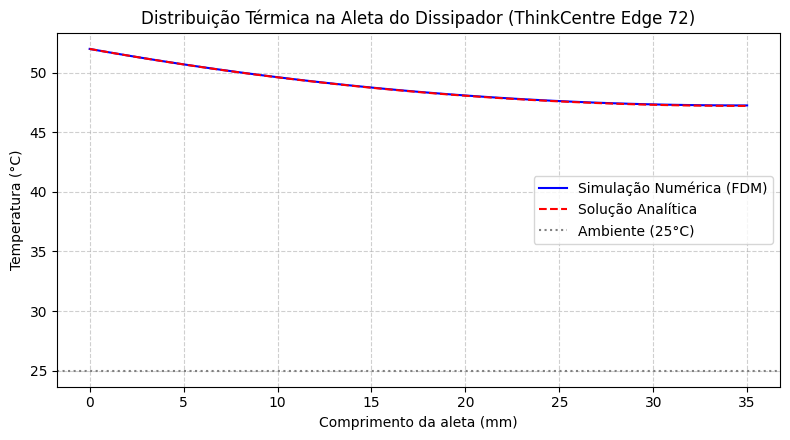

Temperatura calculada na ponta da aleta: 47.26 °C


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parâmetros físicos do sistema ThinkCentre Edge 72
L = 0.035          # Altura da aleta em metros (35 mm)
w = 0.08           # Largura (80 mm)
t = 0.0015         # Espessura da aleta (1.5 mm)
P = 2 * (w + t)    # Perímetro da aleta (m)
A_c = w * t        # Área da seção transversal (m^2)

k = 180.0          # Condutividade térmica do Alumínio 6063 (W/m.K)
h = 45.0           # Coeficiente de convecção forçada do cooler (W/m^2.K)
T_amb = 25.0       # Temperatura ambiente (°C)
T_base = 52.0      # Temperatura medida no teste real de estresse (°C)

# Discretização (Diferenças Finitas 1D)
N = 100
dx = L / (N - 1)
x = np.linspace(0, L, N)

# Parâmetro da aleta m^2 = (h * P) / (k * A_c)
m2 = (h * P) / (k * A_c)
m = np.sqrt(m2)

# Solução Numérica: Sistema Tridiagonal A * T = B
A = np.zeros((N, N))
B = np.zeros(N)

# Condição de contorno na base (x = 0): T = T_base
A[0, 0] = 1.0
B[0] = T_base

# Pontos internos: (T[i+1] - 2*T[i] + T[i-1]) / dx^2 - m^2 * (T[i] - T_amb) = 0
for i in range(1, N - 1):
    A[i, i - 1] = 1.0 / dx**2
    A[i, i] = -2.0 / dx**2 - m2
    A[i, i + 1] = 1.0 / dx**2
    B[i] = -m2 * T_amb

# Condição de contorno na ponta (x = L): Ponta isolada/convectiva simplificada
A[-1, -1] = 1.0
A[-1, -2] = -1.0
B[-1] = 0.0

T_numerica = np.linalg.solve(A, B)

# Solução Analítica clássica de aleta com ponta adiabática
theta_b = T_base - T_amb
T_analitica = T_amb + theta_b * (np.cosh(m * (L - x)) / np.cosh(m * L))

# Gráfico
plt.figure(figsize=(8, 4.5))
plt.plot(x * 1000, T_numerica, 'b-', label='Simulação Numérica (FDM)')
plt.plot(x * 1000, T_analitica, 'r--', label='Solução Analítica')
plt.axhline(T_amb, color='gray', linestyle=':', label='Ambiente (25°C)')
plt.title('Distribuição Térmica na Aleta do Dissipador (ThinkCentre Edge 72)')
plt.xlabel('Comprimento da aleta (mm)')
plt.ylabel('Temperatura (°C)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('validacao_aleta.png', dpi=300)
plt.show()

print(f"Temperatura calculada na ponta da aleta: {T_numerica[-1]:.2f} °C")